In [1]:
# ============================================================================
# CELL 1: SETUP & IMPORTS
# ============================================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
import zipfile
import shutil
import random
import json
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

print("✅ TensorFlow version:", tf.__version__)
print("✅ GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)

# Kaggle paths
BASE_PATH = "/"
INPUT_PATH = "./datasets/"

c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:266: FutureWarning: You are using a Python version (3.10.11) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


✅ TensorFlow version: 2.16.1
✅ GPU Available: False


In [2]:
# ============================================================================
# CELL 2: LOCATE DATASETS (KAGGLE INPUT)
# ============================================================================

print("📦 Locating datasets...\n")

# Cattle dataset - direct from Kaggle input
CATTLE_RAW = f"{INPUT_PATH}cattle-disease"

# if os.path.exists(CATTLE_RAW):
#     print(f"✅ Cattle dataset found at {CATTLE_RAW}")
#     cattle_contents = os.listdir(CATTLE_RAW)
#     print(f"   Contents: {cattle_contents[:5]}...")  # Show first 5 items
# else:
#     print(f"⚠️  Cattle dataset not found at {CATTLE_RAW}")
#     print(f"   Available inputs: {os.listdir(INPUT_PATH)}")

# Pet dataset - direct from Kaggle input
PET_RAW = f"{INPUT_PATH}pet-disease-images"

if os.path.exists(PET_RAW):
    print(f"✅ Pet dataset found at {PET_RAW}")
    pet_contents = os.listdir(PET_RAW)
    print(f"   Contents: {pet_contents[:5]}...")  # Show first 5 items
else:
    print(f"⚠️  Pet dataset not found at {PET_RAW}")
    print(f"   Available inputs: {os.listdir(INPUT_PATH)}")

print("\n" + "="*70 + "\n")

📦 Locating datasets...

✅ Pet dataset found at ./datasets/pet-disease-images
   Contents: ['Dental Disease in Cat', 'Dental Disease in Dog', 'Distemper in Dog', 'Ear Mites in Cat', 'Eye Infection in Cat']...




In [3]:
# ============================================================================
# CELL 3: VALIDATE & CLEAN IMAGES
# ============================================================================

def validate_and_clean_images(root_path):
    """Remove corrupted images"""
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    removed = 0
    
    for root, dirs, files in os.walk(root_path):
        for file in files:
            filepath = os.path.join(root, file)
            
            # Check extension
            if not file.lower().endswith(valid_extensions):
                try:
                    os.remove(filepath)
                    removed += 1
                except:
                    pass
                continue
            
            # Try to load image
            try:
                img = tf.io.read_file(filepath)
                tf.image.decode_image(img, channels=3)
            except:
                try:
                    os.remove(filepath)
                    removed += 1
                except:
                    pass
    
    return removed

print("🔍 Validating images...\n")

# if os.path.exists(CATTLE_RAW):
#     removed = validate_and_clean_images(CATTLE_RAW)
#     print(f"❌ Removed {removed} corrupted cattle images")

if os.path.exists(PET_RAW):
    removed = validate_and_clean_images(PET_RAW)
    print(f"❌ Removed {removed} corrupted pet images")

print("\n" + "="*70 + "\n")

🔍 Validating images...

❌ Removed 3 corrupted cattle images
❌ Removed 87 corrupted pet images




In [40]:
# ============================================================================
# CELL 4: PREPARE CATTLE DATASET
# ============================================================================

print("🐄 PREPARING CATTLE DATASET")
print("="*70 + "\n")

CATTLE_CLEAN = f"{BASE_PATH}/cattle_clean"

# Class mapping for cattle
CATTLE_MAP = {
    'healthy': 'healthy',
    'lumpy': 'lumpy_skin',
    'skin': 'lumpy_skin',
    'ecthym': 'ecthym',
    'dermatitis': 'skin_disease',
    'respiratory': 'respiratory_disease',
    'brd': 'respiratory_disease',
    'contagious': 'skin_disease'
}

def normalize_cattle_class(name):
    name = name.lower()
    for key, value in CATTLE_MAP.items():
        if key in name:
            return value
    return None

# First, check the actual structure
print("🔍 Checking cattle dataset structure...")
if os.path.exists(CATTLE_RAW):
    cattle_structure = os.listdir(CATTLE_RAW)
    print(f"   Found: {cattle_structure}\n")
    
    # Check if splits exist
    has_splits = all(os.path.exists(f"{CATTLE_RAW}/{s}") for s in ['train', 'valid', 'test'])
    
    if has_splits:
        print("✅ Found train/valid/test splits\n")
        # Process with splits
        for split in ['train', 'valid', 'test']:
            src_split = f"{CATTLE_RAW}/{split}"
            if not os.path.exists(src_split):
                continue
            
            for class_folder in os.listdir(src_split):
                src_class_path = os.path.join(src_split, class_folder)
                
                if not os.path.isdir(src_class_path):
                    continue
                
                clean_class = normalize_cattle_class(class_folder)
                if clean_class is None:
                    print(f"⚠️  Skipping unknown class: {class_folder}")
                    continue
                
                dst_class_path = f"{CATTLE_CLEAN}/{split}/{clean_class}"
                os.makedirs(dst_class_path, exist_ok=True)
                
                # Copy images
                img_count = 0
                for img in os.listdir(src_class_path):
                    if img.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                        try:
                            shutil.copy2(
                                os.path.join(src_class_path, img),
                                os.path.join(dst_class_path, img)
                            )
                            img_count += 1
                        except:
                            pass
                
                if img_count > 0:
                    print(f"   {split}/{class_folder} → {clean_class}: {img_count} images")
    else:
        print("⚠️  No standard splits found. Creating splits from available data...\n")
        # Find all class folders in root
        all_classes = {}
        for item in os.listdir(CATTLE_RAW):
            item_path = os.path.join(CATTLE_RAW, item)
            if os.path.isdir(item_path):
                clean_class = normalize_cattle_class(item)
                if clean_class:
                    images = [f for f in os.listdir(item_path) 
                             if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
                    if len(images) > 0:
                        all_classes[item] = (clean_class, images)
        
        # Split data: 70% train, 15% valid, 15% test
        for raw_class, (clean_class, images) in all_classes.items():
            random.shuffle(images)
            n_train = int(len(images) * 0.7)
            n_valid = int(len(images) * 0.15)
            
            splits_data = {
                'train': images[:n_train],
                'valid': images[n_train:n_train+n_valid],
                'test': images[n_train+n_valid:]
            }
            
            for split, img_list in splits_data.items():
                if len(img_list) == 0:
                    continue
                    
                dst_class_path = f"{CATTLE_CLEAN}/{split}/{clean_class}"
                os.makedirs(dst_class_path, exist_ok=True)
                
                for img in img_list:
                    try:
                        shutil.copy2(
                            os.path.join(CATTLE_RAW, raw_class, img),
                            os.path.join(dst_class_path, img)
                        )
                    except:
                        pass
            
            print(f"   {raw_class} → {clean_class}: {len(images)} images")

print("\n📊 Cattle Dataset Statistics:\n")
for split in ['train', 'valid', 'test']:
    split_path = f"{CATTLE_CLEAN}/{split}"
    if os.path.exists(split_path):
        print(f"{split.upper()}:")
        for cls in sorted(os.listdir(split_path)):
            cls_path = f"{split_path}/{cls}"
            if os.path.isdir(cls_path):
                count = len(os.listdir(cls_path))
                print(f"  {cls:25s}: {count:4d} images")
        print()

print("="*70 + "\n")

🐄 PREPARING CATTLE DATASET

🔍 Checking cattle dataset structure...
   Found: ['README.dataset.txt', 'README.roboflow.txt', 'valid', 'test', 'train']

✅ Found train/valid/test splits

   train/Dermatitis Ecthym lumpy skin → lumpy_skin: 2 images
⚠️  Skipping unknown class: Unlabeled
   train/Ecthym skin → lumpy_skin: 2 images
   train/healthy → healthy: 554 images
   train/(BRD) Disease Ecthym → ecthym: 2 images
   train/Contagious Dermatitis lumpy skin → lumpy_skin: 2 images
   train/lumpy skin → lumpy_skin: 570 images
   valid/Dermatitis → skin_disease: 3 images
   valid/(BRD) Bovine Dermatitis Disease healthy lumpy → healthy: 1 images
   valid/healthy → healthy: 90 images
   valid/(BRD) Bovine Disease Respiratory → respiratory_disease: 11 images
   valid/healthy lumpy skin → healthy: 1 images
   valid/lumpy skin → lumpy_skin: 74 images
   valid/Contagious Ecthym → ecthym: 6 images
   test/healthy → healthy: 39 images
   test/lumpy skin → lumpy_skin: 42 images

📊 Cattle Dataset Statist

In [5]:
# ============================================================================
# CELL 5: PREPARE PET DATASET
# ============================================================================

print("PREPARING PET DATASET")
print("="*70 + "\n")

PET_CLEAN = f"{BASE_PATH}/pet_clean"

# Class mapping for pets
PET_MAP = {
    'dental': 'dental_disease',
    'distemper': 'distemper',
    'ear': 'ear_infection',
    'eye': 'eye_infection',
    'feline leukemia': 'feline_leukemia',
    'feline panleukopenia': 'feline_panleukopenia',
    'fungal': 'fungal_infection',
    'hot spots': 'hot_spots',
    'kennel cough': 'kennel_cough',
    'mange': 'mange',
    'parvovirus': 'parvovirus',
    'ringworm': 'ringworm',
    'scabies': 'scabies',
    'skin allergy': 'skin_allergy',
    'tick': 'tick_infestation',
    'urinary': 'urinary_infection',
    'worm': 'worm_infection'
}

def normalize_pet_class(name):
    name = name.lower()
    for key, value in PET_MAP.items():
        if key in name:
            return value
    return None

# Process pet dataset
pet_data_path = f"{PET_RAW}"

if os.path.exists(pet_data_path):
    all_classes = [d for d in os.listdir(pet_data_path) 
                   if os.path.isdir(os.path.join(pet_data_path, d))]
    
    for raw_class in all_classes:
        src_path = os.path.join(pet_data_path, raw_class)
        clean_class = normalize_pet_class(raw_class)
        
        if clean_class is None:
            continue
        
        # Get all images
        images = [f for f in os.listdir(src_path) 
                 if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        
        if len(images) == 0:
            continue
        
        # Split: 70% train, 15% valid, 15% test
        random.shuffle(images)
        n_train = int(len(images) * 0.7)
        n_valid = int(len(images) * 0.15)
        
        train_imgs = images[:n_train]
        valid_imgs = images[n_train:n_train+n_valid]
        test_imgs = images[n_train+n_valid:]
        
        # Copy to respective directories
        for split, img_list in [('train', train_imgs), 
                                ('valid', valid_imgs), 
                                ('test', test_imgs)]:
            dst_path = f"{PET_CLEAN}/{split}/{clean_class}"
            os.makedirs(dst_path, exist_ok=True)
            
            for img in img_list:
                try:
                    shutil.copy2(
                        os.path.join(src_path, img),
                        os.path.join(dst_path, img)
                    )
                except:
                    pass

# Count pet images
print("📊 Pet Dataset Statistics:\n")
for split in ['train', 'valid', 'test']:
    split_path = f"{PET_CLEAN}/{split}"
    if os.path.exists(split_path):
        print(f"{split.upper()}:")
        for cls in sorted(os.listdir(split_path)):
            count = len(os.listdir(f"{split_path}/{cls}"))
            print(f"  {cls:25s}: {count:4d} images")
        print()

print("="*70 + "\n")

PREPARING PET DATASET



FileNotFoundError: [WinError 53] The network path was not found: '//pet_clean/train/'

In [41]:
# ============================================================================
# CELL 6: DATA AUGMENTATION & MODEL ARCHITECTURE
# ============================================================================
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
LEARNING_RATE = 0.001

# Data augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
])

def create_model(num_classes, trainable_base=False):
    """
    Create MobileNetV2-based classifier
    """

    base_model = MobileNetV2(
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
        include_top=False,
        weights="imagenet"
    )

    base_model.trainable = trainable_base

    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="cattle_model")

    return model

print("✅ Model architecture defined")
print("✅ Data augmentation configured\n")

✅ Model architecture defined
✅ Data augmentation configured



In [42]:
# 🔒 Final cattle class list (2-class model)
CATTLE_CLASSES = ['healthy', 'lumpy_skin']
NUM_CATTLE_CLASSES = len(CATTLE_CLASSES)

print(f"🐄 Cattle model classes ({NUM_CATTLE_CLASSES}): {CATTLE_CLASSES}")


🐄 Cattle model classes (2): ['healthy', 'lumpy_skin']


In [43]:
import shutil
import os

FILTERED_CATTLE_DIR = f"{BASE_PATH}/cattle_filtered_2class"

def build_filtered_cattle(src_root, dst_root, allowed_classes):
    if os.path.exists(dst_root):
        shutil.rmtree(dst_root)
    os.makedirs(dst_root, exist_ok=True)

    for split in ["train", "valid", "test"]:
        split_src = os.path.join(src_root, split)
        split_dst = os.path.join(dst_root, split)
        os.makedirs(split_dst, exist_ok=True)

        for cls in allowed_classes:
            src_cls = os.path.join(split_src, cls)
            dst_cls = os.path.join(split_dst, cls)

            if not os.path.exists(src_cls):
                continue

            os.makedirs(dst_cls, exist_ok=True)

            for img in os.listdir(src_cls):
                shutil.copy(
                    os.path.join(src_cls, img),
                    os.path.join(dst_cls, img)
                )

build_filtered_cattle(CATTLE_CLEAN, FILTERED_CATTLE_DIR, CATTLE_CLASSES)

print("✅ Filtered 2-class cattle dataset created")


✅ Filtered 2-class cattle dataset created


In [44]:
cattle_model = create_model(NUM_CATTLE_CLASSES)
cattle_model.summary()

Model: "cattle_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,591,554 (9.89 MB)

 Trainable params: 331,010 (1.26 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [45]:
IMG_SIZE = (224, 224)

In [46]:
# ============================================================================
# CELL 7: TRAIN CATTLE MODEL (FIXED – 2 CLASSES)
# ============================================================================

print("="*70)
print("🐄 TRAINING CATTLE DISEASE MODEL")
print("="*70 + "\n")

# ------------------------------------------------------------------
# Pre-flight checks (filtered dataset, NOT raw)
# ------------------------------------------------------------------
for split in ["train", "valid", "test"]:
    path = f"{FILTERED_CATTLE_DIR}/{split}"
    if not os.path.exists(path):
        raise FileNotFoundError(f"❌ Missing filtered cattle data: {path}")

train_classes = sorted(os.listdir(f"{FILTERED_CATTLE_DIR}/train"))
valid_classes = sorted(os.listdir(f"{FILTERED_CATTLE_DIR}/valid"))
test_classes  = sorted(os.listdir(f"{FILTERED_CATTLE_DIR}/test"))

print("🔍 Pre-flight checks:")
print(f"   Train classes: {len(train_classes)} - {train_classes}")
print(f"   Valid classes: {len(valid_classes)} - {valid_classes}")
print(f"   Test  classes: {len(test_classes)} - {test_classes}\n")

# ------------------------------------------------------------------
# Load datasets (2 classes guaranteed)
# ------------------------------------------------------------------
train_cattle = keras.utils.image_dataset_from_directory(
    f"{FILTERED_CATTLE_DIR}/train",
    image_size=(IMG_SIZE[0], IMG_SIZE[1]),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

val_cattle = keras.utils.image_dataset_from_directory(
    f"{FILTERED_CATTLE_DIR}/valid",
    image_size=(IMG_SIZE[0], IMG_SIZE[1]),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_cattle = keras.utils.image_dataset_from_directory(
    f"{FILTERED_CATTLE_DIR}/test",
    image_size=(IMG_SIZE[0], IMG_SIZE[1]),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

CATTLE_CLASSES = train_cattle.class_names
NUM_CATTLE_CLASSES = len(CATTLE_CLASSES)

print(f"\n✅ Datasets loaded successfully")
print(f"📊 Cattle Classes ({NUM_CATTLE_CLASSES}): {CATTLE_CLASSES}\n")

# ------------------------------------------------------------------
# Performance optimization
# ------------------------------------------------------------------
AUTOTUNE = tf.data.AUTOTUNE
train_cattle = train_cattle.cache().prefetch(AUTOTUNE)
val_cattle   = val_cattle.cache().prefetch(AUTOTUNE)
test_cattle  = test_cattle.cache().prefetch(AUTOTUNE)

# ------------------------------------------------------------------
# Compute class weights (SAFE)
# ------------------------------------------------------------------
cattle_labels = []
for _, labels in train_cattle:
    cattle_labels.extend(np.argmax(labels.numpy(), axis=1))

cattle_labels = np.array(cattle_labels)

cattle_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(cattle_labels),
    y=cattle_labels
)

cattle_weight_dict = {
    int(cls): float(w)
    for cls, w in zip(np.unique(cattle_labels), cattle_class_weights)
}

for i in range(NUM_CATTLE_CLASSES):
    cattle_weight_dict.setdefault(i, 1.0)

print("⚖️  Class weights:")
for i, cls in enumerate(CATTLE_CLASSES):
    print(f"   {cls:20s}: {cattle_weight_dict[i]:.3f}")
print()

# ------------------------------------------------------------------
# Create model (ONLY ONCE)
# ------------------------------------------------------------------
cattle_model = create_model(NUM_CATTLE_CLASSES, trainable_base=False)
cattle_model.summary()

# ------------------------------------------------------------------
# STAGE 1: FEATURE EXTRACTION
# ------------------------------------------------------------------
cattle_model.compile(
    optimizer=keras.optimizers.Adam(3e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\n🚀 Stage 1: Feature Extraction\n")

history_cattle_s1 = cattle_model.fit(
    train_cattle,
    validation_data=val_cattle,
    epochs=10,
    class_weight=cattle_weight_dict,
    verbose=1
)

# ------------------------------------------------------------------
# STAGE 2: PARTIAL FINE-TUNING
# ------------------------------------------------------------------
print("\n🚀 Stage 2: Fine-tuning\n")

# Extract base model SAFELY
base_model = next(
    layer for layer in cattle_model.layers
    if isinstance(layer, keras.Model)
)

base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.7)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

cattle_model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_cattle_s2 = cattle_model.fit(
    train_cattle,
    validation_data=val_cattle,
    epochs=15,
    class_weight=cattle_weight_dict,
    verbose=1
)

print("\n✅ Cattle model training complete\n")

# Always save final model explicitly
cattle_model.save(f"{BASE_PATH}/cattle_model_final.keras")
print("✅ Final cattle model saved explicitly")

# Load best available model
model_path = f"{BASE_PATH}/cattle_model_final.keras"
if not os.path.exists(model_path):
    print("⚠️  Final model not found, loading Stage 1 model instead")
    model_path = f"{BASE_PATH}/cattle_model_stage1.keras"

cattle_model = keras.models.load_model(model_path)



🐄 TRAINING CATTLE DISEASE MODEL

🔍 Pre-flight checks:
   Train classes: 2 - ['healthy', 'lumpy_skin']
   Valid classes: 2 - ['healthy', 'lumpy_skin']
   Test  classes: 2 - ['healthy', 'lumpy_skin']

Found 1130 files belonging to 2 classes.
Found 166 files belonging to 2 classes.
Found 81 files belonging to 2 classes.

✅ Datasets loaded successfully
📊 Cattle Classes (2): ['healthy', 'lumpy_skin']

⚖️  Class weights:
   healthy             : 1.020
   lumpy_skin          : 0.981



Model: "cattle_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,591,554 (9.89 MB)

 Trainable params: 331,010 (1.26 MB)

 Non-trainable params: 2,260,544 (8.62 MB)


🚀 Stage 1: Feature Extraction

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 21s 339ms/step - accuracy: 0.6619 - loss: 0.7448 - val_accuracy: 0.8253 - val_loss: 0.3741
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9007 - loss: 0.2400 - val_accuracy: 0.8072 - val_loss: 0.3776
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.9430 - loss: 0.1541 - val_accuracy: 0.8313 - val_loss: 0.3222
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.9692 - loss: 0.1048 - val_accuracy: 0.8614 - val_loss: 0.2845
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.9739 - loss: 0.0961 - val_accuracy: 0.8976 - val_loss: 0.2577
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.9856 - loss: 0.0679 - val_accuracy: 0.9036 - val_loss: 0.2410
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.9804 - loss: 0.0605 - val_accuracy: 0.8976 - val_loss: 0.2442
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.9906 - loss:

In [47]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y_true = []
y_prob = []

for imgs, labels in test_cattle:
    probs = cattle_model.predict(imgs, verbose=0).ravel()
    y_prob.extend(probs)
    y_true.extend(labels.numpy().astype(int).ravel())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

print("\n🎯 Threshold Tuning:\n")

best_acc = 0
best_th = 0.5

for th in np.arange(0.2, 0.81, 0.05):
    y_pred = (y_prob >= th).astype(int)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    print(f"Threshold {th:.2f} → Acc: {acc:.4f}, F1: {f1:.4f}")

    if acc > best_acc:
        best_acc = acc
        best_th = th

print("\n✅ Best Threshold:", best_th)
print("✅ Best Accuracy :", best_acc)



🎯 Threshold Tuning:

Threshold 0.20 → Acc: 0.7407, F1: 0.7500
Threshold 0.25 → Acc: 0.7531, F1: 0.7590
Threshold 0.30 → Acc: 0.7407, F1: 0.7439
Threshold 0.35 → Acc: 0.7346, F1: 0.7362
Threshold 0.40 → Acc: 0.7407, F1: 0.7407
Threshold 0.45 → Acc: 0.7407, F1: 0.7407
Threshold 0.50 → Acc: 0.7407, F1: 0.7407
Threshold 0.55 → Acc: 0.7407, F1: 0.7407
Threshold 0.60 → Acc: 0.7407, F1: 0.7407
Threshold 0.65 → Acc: 0.7346, F1: 0.7329
Threshold 0.70 → Acc: 0.7407, F1: 0.7375
Threshold 0.75 → Acc: 0.7531, F1: 0.7468
Threshold 0.80 → Acc: 0.7407, F1: 0.7308

✅ Best Threshold: 0.25
✅ Best Accuracy : 0.7530864197530864


In [48]:
CATTLE_CLASSES = ["healthy", "lumpy_skin"]

import json
with open("/kaggle/working/cattle_classes.json", "w") as f:
    json.dump(CATTLE_CLASSES, f)

print("🔒 Locked class order:", CATTLE_CLASSES)


🔒 Locked class order: ['healthy', 'lumpy_skin']


📊 CATTLE MODEL EVALUATION

🎯 Test Results:
   Accuracy: 0.7407 (74.07%)
   Loss: 1.8710

📋 Classification Report:

              precision    recall  f1-score   support

     healthy     0.9500    0.4872    0.6441        39
  lumpy_skin     0.6721    0.9762    0.7961        42

    accuracy                         0.7407        81
   macro avg     0.8111    0.7317    0.7201        81
weighted avg     0.8059    0.7407    0.7229        81

📊 F1-Scores:
   Weighted: 0.7229
   Macro   : 0.7201



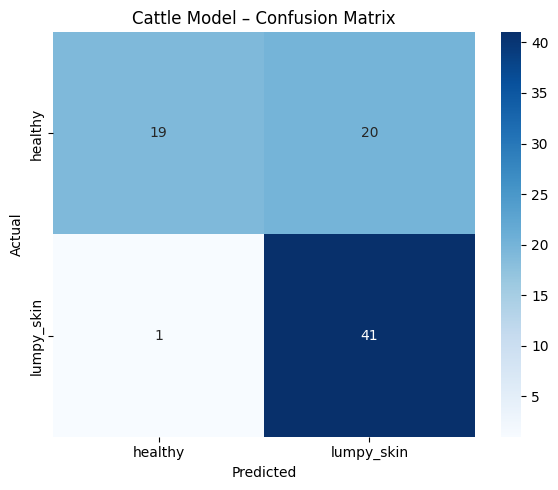


✅ Evaluation complete



In [49]:
# ============================================================================
# CELL 8: EVALUATE CATTLE MODEL (FIXED – 2 CLASS)
# ============================================================================

import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tensorflow import keras

print("="*70)
print("📊 CATTLE MODEL EVALUATION")
print("="*70 + "\n")

# --------------------------------------------------
# Load trained model
# --------------------------------------------------
cattle_model = keras.models.load_model(
    f"{BASE_PATH}/cattle_model_final.keras"
)

# --------------------------------------------------
# Evaluate on test set
# --------------------------------------------------
test_loss, test_acc = cattle_model.evaluate(test_cattle, verbose=0)

print("🎯 Test Results:")
print(f"   Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"   Loss: {test_loss:.4f}\n")

# --------------------------------------------------
# Predictions
# --------------------------------------------------
y_true = []
y_pred = []

for imgs, labels in test_cattle:
    preds = cattle_model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# --------------------------------------------------
# Classification Report
# --------------------------------------------------
print("📋 Classification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CATTLE_CLASSES,
        digits=4
    )
)

# --------------------------------------------------
# F1 Scores
# --------------------------------------------------
f1_weighted = f1_score(y_true, y_pred, average="weighted")
f1_macro = f1_score(y_true, y_pred, average="macro")

print("📊 F1-Scores:")
print(f"   Weighted: {f1_weighted:.4f}")
print(f"   Macro   : {f1_macro:.4f}\n")

# --------------------------------------------------
# Confusion Matrix
# --------------------------------------------------
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CATTLE_CLASSES,
    yticklabels=CATTLE_CLASSES
)
plt.title("Cattle Model – Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/cattle_confusion_matrix.png", dpi=300)
plt.show()

# --------------------------------------------------
# Save class names
# --------------------------------------------------
with open(f"{BASE_PATH}/cattle_classes.json", "w") as f:
    json.dump(CATTLE_CLASSES, f)

print("\n✅ Evaluation complete")
print("="*70 + "\n")


In [ ]:
assert os.path.exists(MODEL_PATH), "❌ Cattle model not found"

cattle_model = keras.models.load_model(
    MODEL_PATH,
    compile=False   # 🔥 prevents loss deserialization issues
)

print("✅ Cattle model loaded")


In [60]:
def predict_cattle_disease(img_path, threshold=0.45, show_image=True):
    img = preprocess_image(img_path)
    preds = cattle_model.predict(img, verbose=0)

    # CASE 1: Softmax model (2 outputs)
    if preds.shape[-1] == 2:
        idx = np.argmax(preds[0])
        prob = preds[0][idx]
        pred_class = CLASS_NAMES[idx]

    # CASE 2: Sigmoid model (1 output)
    else:
        prob = preds[0][0]
        pred_class = "lumpy_skin" if prob >= threshold else "healthy"
        prob = prob if pred_class == "lumpy_skin" else 1 - prob

    print("\n🐄 CATTLE MODEL RESULT")
    print("-" * 40)
    print(f"Prediction : {pred_class}")
    print(f"Confidence : {prob * 100:.2f}%")
    print(f"Threshold  : {threshold}")

    if show_image:
        plt.imshow(plt.imread(img_path))
        plt.axis("off")
        plt.title(f"{pred_class.upper()} (p={prob:.2f})")
        plt.show()

    return pred_class, prob


In [61]:
print("Model output shape:", cattle_model.output_shape)


Model output shape: (None, 2)


✅ Cattle model loaded


2025-12-23 13:53:25.364207: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-23 13:53:25.498342: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



🐄 CATTLE MODEL RESULT
----------------------------------------
Prediction : lumpy_skin
Confidence : 100.00%
Threshold  : 0.45


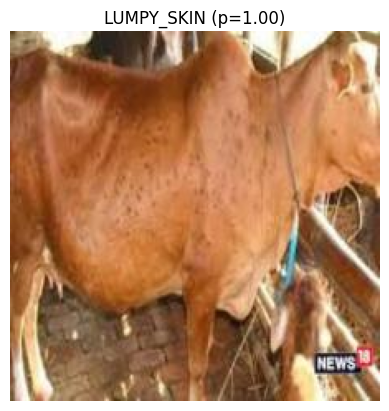

('lumpy_skin', np.float32(1.0))

In [62]:
# ============================================================================
# CATTLE MODEL – SINGLE IMAGE TESTING (LUMPY SKIN vs HEALTHY)
# ============================================================================

import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import os

# ------------------------------
# CONFIG
# ------------------------------
MODEL_PATH = "/kaggle/working/cattle_model_final.keras"
IMG_SIZE = (224, 224)
THRESHOLD = 0.45   # ✅ best threshold you found

CLASS_NAMES = ["healthy", "lumpy_skin"]

assert os.path.exists(MODEL_PATH), "❌ Model file not found"

# ------------------------------
# Load model (SAFE)
# ------------------------------
cattle_model = keras.models.load_model(MODEL_PATH, compile=False)
print("✅ Cattle model loaded")

# ------------------------------
# Image preprocessing
# ------------------------------
def preprocess_image(img_path):
    img = keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img = keras.utils.img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = keras.applications.efficientnet.preprocess_input(img)
    return img

# ------------------------------
# Prediction function
# ------------------------------
@tf.function(reduce_retracing=True)
def model_predict(x):
    return cattle_model(x, training=False)

def predict_cattle_disease(img_path, threshold=0.45, show_image=True):
    img = preprocess_image(img_path)
    preds = cattle_model.predict(img, verbose=0)

    # CASE 1: Softmax model (2 outputs)
    if preds.shape[-1] == 2:
        idx = np.argmax(preds[0])
        prob = preds[0][idx]
        pred_class = CLASS_NAMES[idx]

    # CASE 2: Sigmoid model (1 output)
    else:
        prob = preds[0][0]
        pred_class = "lumpy_skin" if prob >= threshold else "healthy"
        prob = prob if pred_class == "lumpy_skin" else 1 - prob

    print("\n🐄 CATTLE MODEL RESULT")
    print("-" * 40)
    print(f"Prediction : {pred_class}")
    print(f"Confidence : {prob * 100:.2f}%")
    print(f"Threshold  : {threshold}")

    if show_image:
        plt.imshow(plt.imread(img_path))
        plt.axis("off")
        plt.title(f"{pred_class.upper()} (p={prob:.2f})")
        plt.show()

    return pred_class, prob


# ------------------------------
# 🔍 TEST IMAGE (CHANGE THIS)
# ------------------------------
TEST_IMAGE_PATH = "/kaggle/input/cattle-disease/test/lumpy skin/10_jpg.rf.b40d89669d6d71eed8ad9984cd5b1531.jpg"

predict_cattle_disease(TEST_IMAGE_PATH)


In [ ]:
# ============================================================================
# PET CLASS MERGING + SPECIES SPLIT (BULLETPROOF VERSION)
# ============================================================================

import os
import shutil

print("=" * 70)
print("🔄 MERGING PET CLASSES + SPLITTING DOG / CAT (BULLETPROOF)")
print("=" * 70 + "\n")

RAW_PET_PATH = f"/kaggle/input/pet-disease-images/data"
PET_CLEAN = PET_CLEAN  # your existing cleaned dataset

MERGED_PET_DOG = f"{BASE_PATH}/pet_merged_dog"
MERGED_PET_CAT = f"{BASE_PATH}/pet_merged_cat"

# ------------------------------------------------------------------
# Medical class mapping
# ------------------------------------------------------------------
PET_CLASS_MAP = {
    "bacterial_infection": ["ear", "eye", "dental", "urinary"],
    "viral_infection": ["distemper", "parvo", "panleukopenia", "leukemia"],
    "fungal_infection": ["fungal", "ringworm"],
    "parasitic_infestation": ["mange", "scabies", "tick", "worm"],
    "skin_disease": ["skin", "hot"],
    "respiratory_disease": ["cough", "respiratory", "kennel"]
}

# ------------------------------------------------------------------
# Build IMAGE → SPECIES lookup FROM RAW DATA
# ------------------------------------------------------------------
print("🔍 Building image → species map from RAW dataset...")

image_species = {}

for raw_class in os.listdir(RAW_PET_PATH):
    raw_class_lower = raw_class.lower()
    raw_dir = os.path.join(RAW_PET_PATH, raw_class)

    if not os.path.isdir(raw_dir):
        continue

    if "dog" in raw_class_lower:
        species = "dog"
    elif "cat" in raw_class_lower or "feline" in raw_class_lower:
        species = "cat"
    else:
        continue

    for img in os.listdir(raw_dir):
        image_species[img] = species

print(f"✅ Species mapped for {len(image_species)} images\n")

# ------------------------------------------------------------------
# Create output folders
# ------------------------------------------------------------------
for root in [MERGED_PET_DOG, MERGED_PET_CAT]:
    for split in ["train", "valid", "test"]:
        for cls in PET_CLASS_MAP.keys():
            os.makedirs(os.path.join(root, split, cls), exist_ok=True)

# ------------------------------------------------------------------
# Merge CLEANED data using RAW species map
# ------------------------------------------------------------------
dog_count, cat_count, skipped = 0, 0, 0

for split in ["train", "valid", "test"]:
    split_dir = os.path.join(PET_CLEAN, split)

    for cls in os.listdir(split_dir):
        cls_dir = os.path.join(split_dir, cls)

        if not os.path.isdir(cls_dir):
            continue

        cls_lower = cls.lower()

        # Find medical class
        target_class = None
        for new_class, keywords in PET_CLASS_MAP.items():
            if any(k in cls_lower for k in keywords):
                target_class = new_class
                break

        if target_class is None:
            skipped += len(os.listdir(cls_dir))
            continue

        for img in os.listdir(cls_dir):
            species = image_species.get(img)

            if species == "dog":
                dst_root = MERGED_PET_DOG
                dog_count += 1
            elif species == "cat":
                dst_root = MERGED_PET_CAT
                cat_count += 1
            else:
                skipped += 1
                continue

            dst_dir = os.path.join(dst_root, split, target_class)
            os.makedirs(dst_dir, exist_ok=True)

            src = os.path.join(cls_dir, img)
            dst = os.path.join(dst_dir, img)

            if os.path.exists(dst):
                name, ext = os.path.splitext(img)
                dst = os.path.join(dst_dir, f"{name}_dup{ext}")

            shutil.copy(src, dst)

print(f"✅ DOG images moved: {dog_count}")
print(f"✅ CAT images moved: {cat_count}")
print(f"⚠️  Skipped images: {skipped}\n")

# ------------------------------------------------------------------
# Stats
# ------------------------------------------------------------------
def show_stats(root, label):
    print(f"📊 {label.upper()} DATASET")
    for cls in PET_CLASS_MAP.keys():
        count = sum(
            len(os.listdir(os.path.join(root, split, cls)))
            for split in ["train", "valid", "test"]
        )
        print(f"   {cls:25s}: {count}")
    print()

show_stats(MERGED_PET_DOG, "dog")
show_stats(MERGED_PET_CAT, "cat")

print("✅ Merge + species split complete")
print("=" * 70)


In [ ]:
if "dog" in raw_class.lower():
    target_root = MERGED_PET_DOG
elif "cat" in raw_class.lower():
    target_root = MERGED_PET_CAT

In [ ]:
# ===============================
# GLOBAL CONFIG
# ===============================
IMG_SIZE = 224          # ✅ MUST BE INT
BATCH_SIZE = 32
BASE_PATH = "/kaggle/working"
AUTOTUNE = tf.data.AUTOTUNE


In [ ]:
def create_model(num_classes, trainable_base=False):
    base_model = MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),   # ✅ correct
        include_top=False,
        weights="imagenet"
    )

    base_model.trainable = trainable_base

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    return model


In [ ]:
# DEBUG: locate CAT images
import os

print("🔍 Searching for CAT images...\n")

for root, dirs, files in os.walk(BASE_PATH):
    if "cat" in root.lower():
        img_count = len([f for f in files if f.lower().endswith((".jpg",".png",".jpeg",".bmp"))])
        if img_count > 0:
            print(root, "→", img_count)


In [26]:
# ============================================================================
# CELL 1: LOAD DOG DATASET
# ============================================================================

print("=" * 70)
print("🐕 LOADING DOG DISEASE DATASET")
print("=" * 70 + "\n")

DOG_DIR = MERGED_PET_DOG   # <-- confirm this path exists

train_dog = keras.utils.image_dataset_from_directory(
    f"{DOG_DIR}/train",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

DOG_CLASSES = train_dog.class_names
NUM_DOG_CLASSES = len(DOG_CLASSES)

print("🔒 Locked DOG Classes:")
for i, cls in enumerate(DOG_CLASSES):
    print(f"   {i}: {cls}")

val_dog = keras.utils.image_dataset_from_directory(
    f"{DOG_DIR}/valid",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_dog = keras.utils.image_dataset_from_directory(
    f"{DOG_DIR}/test",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

print(f"\n📊 Number of classes: {NUM_DOG_CLASSES}")


🐕 LOADING DOG DISEASE DATASET

Found 890 files belonging to 6 classes.
🔒 Locked DOG Classes:
   0: bacterial_infection
   1: fungal_infection
   2: parasitic_infestation
   3: respiratory_disease
   4: skin_disease
   5: viral_infection
Found 224 files belonging to 6 classes.
Found 252 files belonging to 6 classes.

📊 Number of classes: 6


In [27]:
# ============================================================================
# CELL 1: CREATE DOG 2-CLASS DATASET (SKIN vs NON-SKIN)
# ============================================================================

import os, shutil

print("="*70)
print("🐕 CREATING DOG 2-CLASS DATASET (SKIN vs NON-SKIN)")
print("="*70)

DOG_SRC = MERGED_PET_DOG          # existing 6-class dog dataset
DOG_2C  = f"{BASE_PATH}/dog_2class"

SKIN_CLASSES = [
    "skin_disease",
    "fungal_infection",
    "parasitic_infestation"
]

NON_SKIN_CLASSES = [
    "viral_infection",
    "bacterial_infection",
    "respiratory_disease"
]

# Create folders
for split in ["train", "valid", "test"]:
    os.makedirs(f"{DOG_2C}/{split}/skin", exist_ok=True)
    os.makedirs(f"{DOG_2C}/{split}/non_skin", exist_ok=True)

# Move images
count = {"skin": 0, "non_skin": 0}

for split in ["train", "valid", "test"]:
    for cls in SKIN_CLASSES:
        src = f"{DOG_SRC}/{split}/{cls}"
        if os.path.exists(src):
            for img in os.listdir(src):
                shutil.copy(
                    f"{src}/{img}",
                    f"{DOG_2C}/{split}/skin/{cls}_{img}"
                )
                count["skin"] += 1

    for cls in NON_SKIN_CLASSES:
        src = f"{DOG_SRC}/{split}/{cls}"
        if os.path.exists(src):
            for img in os.listdir(src):
                shutil.copy(
                    f"{src}/{img}",
                    f"{DOG_2C}/{split}/non_skin/{cls}_{img}"
                )
                count["non_skin"] += 1

print("✅ Dataset created")
print("📊 Image counts:", count)
print("="*70)


🐕 CREATING DOG 2-CLASS DATASET (SKIN vs NON-SKIN)
✅ Dataset created
📊 Image counts: {'skin': 737, 'non_skin': 629}


In [45]:
# ============================================================================
# CLEAN DOG DATASET (REMOVE NON-IMAGES)
# ============================================================================

import os

VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def clean_dataset(root_dir):
    removed = 0
    for root, _, files in os.walk(root_dir):
        for f in files:
            if not f.lower().endswith(VALID_EXTS):
                path = os.path.join(root, f)
                os.remove(path)
                removed += 1
    return removed

DOG_DIR = f"{BASE_PATH}/dog_2class"

removed = clean_dataset(DOG_DIR)
print(f"🧹 Removed {removed} non-image files from DOG dataset")


🧹 Removed 0 non-image files from DOG dataset


In [49]:
# ============================================================================
# STEP 1: HARD CLEAN DOG DATASET (BULLETPROOF)
# ============================================================================

import os
from PIL import Image

VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def hard_clean_images(root_dir):
    removed = 0
    for root, _, files in os.walk(root_dir):
        for file in files:
            path = os.path.join(root, file)

            # Remove non-image extensions
            if not file.lower().endswith(VALID_EXTS):
                os.remove(path)
                removed += 1
                continue

            # Remove corrupted images
            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception:
                os.remove(path)
                removed += 1

    return removed

DOG_DIR = f"{BASE_PATH}/dog_2class"

removed = hard_clean_images(DOG_DIR)
print(f"🧹 HARD CLEAN DONE — Removed {removed} invalid files")


🧹 HARD CLEAN DONE — Removed 0 invalid files


In [50]:
# ============================================================================
# DOG BINARY MODEL DEFINITION (SIGMOID OUTPUT)
# ============================================================================

from tensorflow import keras
from tensorflow.keras import layers

def create_dog_binary_model(trainable_base=False):
    base_model = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = trainable_base

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Preprocessing
    x = keras.applications.mobilenet_v2.preprocess_input(inputs)

    # Backbone
    x = base_model(x, training=False)

    # Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    # 🔥 SIGMOID OUTPUT (1 neuron)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="dog_skin_binary")

    return model


In [53]:
from tensorflow import keras
from tensorflow.keras import layers

def create_dog_binary_model(trainable_base=False):
    base_model = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )

    base_model.trainable = trainable_base

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)  # 🔥 FIX

    model = keras.Model(inputs, outputs)
    return model


In [54]:
# ============================================================================
# CELL 2 (UPGRADED): TRAIN DOG MODEL (SKIN vs NON-SKIN – SIGMOID)
# ============================================================================

print("="*70)
print("🐕 TRAINING DOG MODEL (SKIN vs NON-SKIN – SIGMOID + FOCAL)")
print("="*70)

DOG_DIR = f"{BASE_PATH}/dog_2class"

# --------------------------------------------------
# DATA LOADING (BINARY LABELS)
# --------------------------------------------------
train_dog = keras.utils.image_dataset_from_directory(
    f"{DOG_DIR}/train",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",   # 🔥 IMPORTANT
    shuffle=True,
    seed=42
)

val_dog = keras.utils.image_dataset_from_directory(
    f"{DOG_DIR}/valid",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_dog = keras.utils.image_dataset_from_directory(
    f"{DOG_DIR}/test",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)


DOG_CLASSES = train_dog.class_names
print("🔒 Locked DOG Classes:", DOG_CLASSES)

train_dog = train_dog.apply(tf.data.experimental.ignore_errors())
val_dog   = val_dog.apply(tf.data.experimental.ignore_errors())
test_dog  = test_dog.apply(tf.data.experimental.ignore_errors())

AUTOTUNE = tf.data.AUTOTUNE
train_dog = train_dog.prefetch(AUTOTUNE)
val_dog   = val_dog.prefetch(AUTOTUNE)
test_dog  = test_dog.prefetch(AUTOTUNE)
# --------------------------------------------------
# SAFE CLASS WEIGHTS (DIRECTORY COUNT — NO IMAGE DECODE)
# --------------------------------------------------
train_dir = f"{DOG_DIR}/train"
class_counts = {}

for idx, cls in enumerate(DOG_CLASSES):
    cls_path = os.path.join(train_dir, cls)
    class_counts[idx] = len([
        f for f in os.listdir(cls_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

total = sum(class_counts.values())

dog_class_weights = {
    cls: total / (2 * max(count, 1))
    for cls, count in class_counts.items()
}

print("⚖️ DOG Class Weights:")
for i, cls in enumerate(DOG_CLASSES):
    print(f"   {cls:12s}: {dog_class_weights[i]:.3f}")

# --------------------------------------------------
# BINARY FOCAL LOSS (BOOSTS HARD SKIN CASES)
# --------------------------------------------------
import tensorflow as tf

def binary_focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        bce = -(y_true * tf.math.log(y_pred) +
                (1 - y_true) * tf.math.log(1 - y_pred))
        p_t = y_true * y_pred + (1 - y_true) * (1 - y_pred)
        alpha_factor = y_true * alpha + (1 - y_true) * (1 - alpha)
        modulating_factor = tf.pow(1.0 - p_t, gamma)
        return tf.reduce_mean(alpha_factor * modulating_factor * bce)
    return loss

# --------------------------------------------------
# MODEL (SIGMOID OUTPUT)
# --------------------------------------------------
dog_model = create_dog_binary_model(trainable_base=False)

dog_model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss=binary_focal_loss(gamma=2.0, alpha=0.35),
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.4,
        patience=4,
        min_lr=1e-6
    ),
    keras.callbacks.ModelCheckpoint(
        f"{BASE_PATH}/dog_skin_sigmoid.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

print("\n🚀 Training DOG binary model...\n")

dog_model.fit(
    train_dog,
    validation_data=val_dog,
    epochs=20,
    class_weight=dog_class_weights,
    callbacks=callbacks,
    verbose=1
)

dog_model.save(f"{BASE_PATH}/dog_skin_sigmoid.keras")
print("\n✅ Dog binary model trained successfully")


🐕 TRAINING DOG MODEL (SKIN vs NON-SKIN – SIGMOID + FOCAL)
Found 890 files belonging to 2 classes.
Found 224 files belonging to 2 classes.
Found 252 files belonging to 2 classes.
🔒 Locked DOG Classes: ['non_skin', 'skin']
⚖️ DOG Class Weights:
   non_skin    : 1.080
   skin        : 0.931

🚀 Training DOG binary model...

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 768ms/step - accuracy: 0.5080 - loss: 0.2033 - val_accuracy: 0.5625 - val_loss: 0.1410 - learning_rate: 1.0000e-04
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 268ms/step - accuracy: 0.5725 - loss: 0.1635 - val_accuracy: 0.6354 - val_loss: 0.1293 - learning_rate: 1.0000e-04
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 241ms/step - accuracy: 0.5687 - loss: 0.1594 - val_accuracy: 0.6458 - val_loss: 0.1227 - learning_rate: 1.0000e-04
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 231ms/step - accuracy: 0.6463 - loss: 0.1453 - val_accuracy: 0.6354 - val_loss: 0.1174 - learning_rate: 1.0000e-04
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 226ms/step -

📊 DOG MODEL EVALUATION (SKIN vs NON-SKIN)
🎯 Accuracy: 70.16%
📉 Loss    : 0.5824

📋 Classification Report:

              precision    recall  f1-score   support

    non_skin     0.8438    0.4219    0.5625        64
        skin     0.5978    0.9167    0.7237        60

    accuracy                         0.6613       124
   macro avg     0.7208    0.6693    0.6431       124
weighted avg     0.7248    0.6613    0.6405       124

📊 F1-Scores:
   Weighted: 0.6405
   Macro   : 0.6431



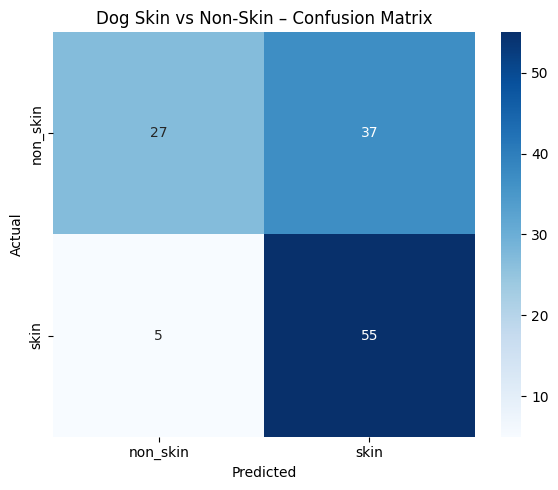

✅ Dog model evaluation complete


In [56]:
# ============================================================================
# CELL 3: EVALUATE DOG MODEL (SKIN vs NON-SKIN) — FINAL & CORRECT
# ============================================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tensorflow import keras
import os

print("="*70)
print("📊 DOG MODEL EVALUATION (SKIN vs NON-SKIN)")
print("="*70)

# --------------------------------------------------
# Load model safely (sigmoid binary)
# --------------------------------------------------
model_path = f"{BASE_PATH}/dog_skin_sigmoid.keras"
assert os.path.exists(model_path), "❌ dog_skin_sigmoid.keras not found"

dog_model = keras.models.load_model(model_path, compile=False)

dog_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# --------------------------------------------------
# Evaluate
# --------------------------------------------------
loss, acc = dog_model.evaluate(test_dog, verbose=0)

print(f"🎯 Accuracy: {acc*100:.2f}%")
print(f"📉 Loss    : {loss:.4f}\n")

# --------------------------------------------------
# Predictions (SIGMOID + THRESHOLD)
# --------------------------------------------------
THRESHOLD = 0.30  # tuned threshold (change later if needed)

y_true, y_pred = [], []

for images, labels in test_dog:
    probs = dog_model.predict(images, verbose=0).ravel()
    y_pred.extend((probs >= THRESHOLD).astype(int))
    y_true.extend(labels.numpy().astype(int).ravel())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

DOG_CLASSES = ["non_skin", "skin"]

# --------------------------------------------------
# Classification Report
# --------------------------------------------------
print("📋 Classification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=DOG_CLASSES,
        digits=4
    )
)

# --------------------------------------------------
# F1 Scores
# --------------------------------------------------
print("📊 F1-Scores:")
print(f"   Weighted: {f1_score(y_true, y_pred, average='weighted'):.4f}")
print(f"   Macro   : {f1_score(y_true, y_pred, average='macro'):.4f}\n")

# --------------------------------------------------
# Confusion Matrix
# --------------------------------------------------
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=DOG_CLASSES,
    yticklabels=DOG_CLASSES
)
plt.title("Dog Skin vs Non-Skin – Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("✅ Dog model evaluation complete")
print("="*70)


In [57]:
# ============================================================================
# CELL 4: SINGLE IMAGE TESTING FUNCTION (DOG SKIN vs NON-SKIN)
# ============================================================================

from tensorflow.keras.preprocessing import image
import numpy as np

def predict_dog_skin(image_path, model, threshold=0.30):
    """
    Predicts whether a dog image shows SKIN or NON-SKIN disease
    """

    img = image.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prob = model.predict(img_array, verbose=0)[0][0]
    label = "skin" if prob >= threshold else "non_skin"

    print("🔍 Prediction Result")
    print(f"   Probability (skin): {prob:.4f}")
    print(f"   Final Class       : {label.upper()}")

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{label.upper()} (p={prob:.2f})")
    plt.show()


2025-12-22 12:41:11.913403: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-22 12:41:12.058650: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-22 12:41:12.192877: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


🔍 Prediction Result
   Probability (skin): 0.4526
   Final Class       : SKIN


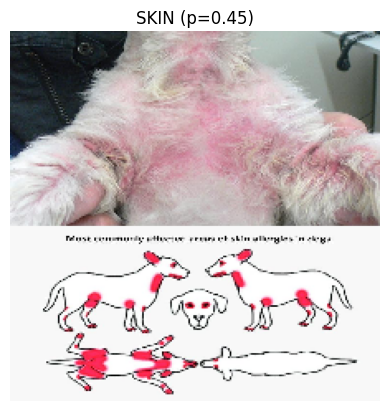

In [58]:
predict_dog_skin(
    image_path="/kaggle/input/pet-disease-images/data/Skin Allergy in Dog/Image_1.jpg",
    model=dog_model,
    threshold=0.30
)


In [29]:
# ============================================================================
# CELL 0: CAT DATASET INSPECTION & PREPROCESSING CHECK
# ============================================================================

import os
from collections import defaultdict
from PIL import Image

print("=" * 70)
print("🔍 CAT DATASET INSPECTION")
print("=" * 70)

# 🔴 CHANGE THIS PATH ONLY
DATASET_ROOT = "/kaggle/input/cat-skin-disease"   # <- update if needed

# Accepted image extensions
VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

# --------------------------------------------------
# Helper: check if image is valid
# --------------------------------------------------
def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

# --------------------------------------------------
# Scan dataset
# --------------------------------------------------
split_stats = defaultdict(lambda: defaultdict(int))
invalid_images = []

for root, dirs, files in os.walk(DATASET_ROOT):
    for file in files:
        if not file.lower().endswith(VALID_EXTS):
            invalid_images.append(os.path.join(root, file))
            continue

        img_path = os.path.join(root, file)
        if not is_valid_image(img_path):
            invalid_images.append(img_path)
            continue

        # Infer split & class
        rel = os.path.relpath(img_path, DATASET_ROOT)
        parts = rel.split(os.sep)

        if len(parts) >= 2:
            split = parts[0]
            cls = parts[1]
        else:
            split = "unknown"
            cls = "unknown"

        split_stats[split][cls] += 1

# --------------------------------------------------
# Display results
# --------------------------------------------------
total_images = 0

for split, classes in split_stats.items():
    print(f"\n📊 SPLIT: {split.upper()}")
    split_total = 0
    for cls, count in sorted(classes.items()):
        print(f"   {cls:25s}: {count}")
        split_total += count
    print(f"   ➜ Total {split}: {split_total}")
    total_images += split_total

print("\n📦 TOTAL IMAGES:", total_images)

# --------------------------------------------------
# Invalid images report
# --------------------------------------------------
print("\n⚠️ INVALID / CORRUPT FILES:", len(invalid_images))
if invalid_images:
    print("   Examples:")
    for p in invalid_images[:5]:
        print("   ", p)

# --------------------------------------------------
# Sanity checks
# --------------------------------------------------
print("\n🧠 SANITY CHECKS:")

for split, classes in split_stats.items():
    min_count = min(classes.values())
    max_count = max(classes.values())
    if min_count < 10:
        print(f"   ⚠️ {split}: Some classes have <10 images (VERY SMALL)")
    if max_count / max(min_count, 1) > 5:
        print(f"   ⚠️ {split}: Strong class imbalance detected")

print("\n✅ Dataset inspection complete")
print("=" * 70)


🔍 CAT DATASET INSPECTION

📊 SPLIT: CAT SKIN DISEASE
   Flea_Allergy             : 250
   Health                   : 250
   Ringworm                 : 249
   Scabies                  : 250
   ➜ Total CAT SKIN DISEASE: 999

📦 TOTAL IMAGES: 999

⚠️ INVALID / CORRUPT FILES: 1
   Examples:
    /kaggle/input/cat-skin-disease/CAT SKIN DISEASE/Ringworm/Ringworm-lesion-in-cat_Yaya-photos_Shutterstock-jpg.webp

🧠 SANITY CHECKS:

✅ Dataset inspection complete


In [1]:
import os
from PIL import Image

DATASET_DIR = "/kaggle/input/cat-skin-disease/CAT SKIN DISEASE"

print("="*70)
print("🔍 CAT DATASET INSPECTION")
print("="*70)

total = 0
bad_files = []

for cls in os.listdir(DATASET_DIR):
    cls_path = os.path.join(DATASET_DIR, cls)
    if not os.path.isdir(cls_path):
        continue

    count = 0
    for f in os.listdir(cls_path):
        fp = os.path.join(cls_path, f)
        try:
            Image.open(fp).verify()
            count += 1
        except:
            bad_files.append(fp)

    print(f"{cls:20s}: {count}")
    total += count

print(f"\n📦 TOTAL IMAGES: {total}")
print(f"⚠️ INVALID FILES: {len(bad_files)}")


🔍 CAT DATASET INSPECTION
Health              : 250
Flea_Allergy        : 250
Scabies             : 250
Ringworm            : 250

📦 TOTAL IMAGES: 1000
⚠️ INVALID FILES: 0


In [2]:
import os
import shutil
import random

SRC_DIR = "/kaggle/input/cat-skin-disease/CAT SKIN DISEASE"
DEST_DIR = "/kaggle/working/cat_skin_binary"

SPLITS = {"train": 0.7, "valid": 0.15, "test": 0.15}
SKIN_CLASSES = ["Flea_Allergy", "Ringworm", "Scabies"]
NON_SKIN_CLASSES = ["Health"]

random.seed(42)

# Create folder structure
for split in SPLITS:
    for cls in ["skin", "non_skin"]:
        os.makedirs(f"{DEST_DIR}/{split}/{cls}", exist_ok=True)

def split_and_copy(images, label):
    random.shuffle(images)
    n = len(images)
    train_end = int(n * SPLITS["train"])
    valid_end = int(n * (SPLITS["train"] + SPLITS["valid"]))

    splits = {
        "train": images[:train_end],
        "valid": images[train_end:valid_end],
        "test": images[valid_end:]
    }

    for split, files in splits.items():
        for f in files:
            src = f
            dst = f"{DEST_DIR}/{split}/{label}/{os.path.basename(f)}"
            shutil.copy(src, dst)

# ---- SKIN ----
skin_images = []
for cls in SKIN_CLASSES:
    cls_dir = os.path.join(SRC_DIR, cls)
    for f in os.listdir(cls_dir):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            skin_images.append(os.path.join(cls_dir, f))

split_and_copy(skin_images, "skin")

# ---- NON-SKIN ----
non_skin_images = []
for cls in NON_SKIN_CLASSES:
    cls_dir = os.path.join(SRC_DIR, cls)
    for f in os.listdir(cls_dir):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            non_skin_images.append(os.path.join(cls_dir, f))

# Balance non-skin to skin count
non_skin_images = non_skin_images[:len(skin_images)]
split_and_copy(non_skin_images, "non_skin")

print("✅ CAT skin vs non-skin dataset created")


✅ CAT skin vs non-skin dataset created


In [3]:
from collections import Counter

print("\n📊 FINAL DATASET DISTRIBUTION\n")

for split in ["train", "valid", "test"]:
    print(f"📁 {split.upper()}")
    for cls in ["skin", "non_skin"]:
        path = f"{DEST_DIR}/{split}/{cls}"
        count = len(os.listdir(path))
        print(f"   {cls:10s}: {count}")
    print()



📊 FINAL DATASET DISTRIBUTION

📁 TRAIN
   skin      : 522
   non_skin  : 175

📁 VALID
   skin      : 112
   non_skin  : 37

📁 TEST
   skin      : 113
   non_skin  : 38



In [4]:
# ============================================================================
# FINAL TRAINING: CAT SKIN vs NON-SKIN
# ============================================================================

import tensorflow as tf
from tensorflow import keras
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
import os

print("="*70)
print("🐈 FINAL TRAINING — CAT SKIN vs NON-SKIN")
print("="*70)

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
BASE_PATH = "/kaggle/working"
CAT_DIR = f"{BASE_PATH}/cat_skin_binary"
IMG_SIZE = 224
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

# ------------------------------------------------------------------
# SAFE DATA AUGMENTATION (medical-safe)
# ------------------------------------------------------------------
augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomContrast(0.2),
])

# ------------------------------------------------------------------
# LOAD DATASETS (BINARY)
# ------------------------------------------------------------------
train_ds = keras.utils.image_dataset_from_directory(
    f"{CAT_DIR}/train",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

val_ds = keras.utils.image_dataset_from_directory(
    f"{CAT_DIR}/valid",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    f"{CAT_DIR}/test",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

CLASS_NAMES = train_ds.class_names
print("🔒 Classes:", CLASS_NAMES)

train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

# ------------------------------------------------------------------
# CLASS WEIGHTS (CRITICAL)
# ------------------------------------------------------------------
labels = []
for _, y in train_ds:
    labels.extend(y.numpy().astype(int).flatten())

labels = np.array(labels)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = {i: w for i, w in enumerate(weights)}
print("⚖️ Class weights:", class_weights)

# ------------------------------------------------------------------
# MODEL
# ------------------------------------------------------------------
base = keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights="imagenet"
)
base.trainable = False  # Stage 1

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = keras.applications.efficientnet.preprocess_input(x)
x = base(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.Dense(256, activation="relu")(x)
x = keras.layers.Dropout(0.4)(x)
outputs = keras.layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ------------------------------------------------------------------
# TRAIN — STAGE 1
# ------------------------------------------------------------------
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        f"{BASE_PATH}/cat_skin_stage1.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

print("\n🚀 Stage 1 Training...\n")

model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

# ------------------------------------------------------------------
# FINE-TUNING (Stage 2)
# ------------------------------------------------------------------
print("\n🚀 Fine-tuning...\n")

base.trainable = True
for layer in base.layers[:int(len(base.layers) * 0.7)]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

model.save(f"{BASE_PATH}/cat_final.keras")
print("\n✅ FINAL MODEL SAVED")


2025-12-23 12:18:50.995037: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766492331.195757      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766492331.252201      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1766492331.740030      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766492331.740071      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766492331.740074      55 computation_placer.cc:177] computation placer alr

🐈 FINAL TRAINING — CAT SKIN vs NON-SKIN
Found 697 files belonging to 2 classes.


I0000 00:00:1766492344.592070      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1766492344.595951      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 149 files belonging to 2 classes.
Found 151 files belonging to 2 classes.
🔒 Classes: ['non_skin', 'skin']
⚖️ Class weights: {0: np.float64(1.9914285714285713), 1: np.float64(0.6676245210727969)}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

...


🚀 Stage 1 Training...

Epoch 1/20


E0000 00:00:1766492358.993099      55 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1766492361.719875     148 cuda_dnn.cc:529] Loaded cuDNN version 91002


44/44 ━━━━━━━━━━━━━━━━━━━━ 20s 155ms/step - accuracy: 0.6858 - auc: 0.6974 - loss: 0.7343 - val_accuracy: 0.8859 - val_auc: 0.9510 - val_loss: 0.3950
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8477 - auc: 0.9324 - loss: 0.3445 - val_accuracy: 0.8926 - val_auc: 0.9762 - val_loss: 0.3252
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.8728 - auc: 0.9550 - loss: 0.2797 - val_accuracy: 0.9195 - val_auc: 0.9888 - val_loss: 0.2777
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.8838 - auc: 0.9686 - loss: 0.2339 - val_accuracy: 0.9195 - val_auc: 0.9911 - val_loss: 0.2362
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.9230 - auc: 0.9802 - loss: 0.1842 - val_accuracy: 0.9262 - val_auc: 0.9916 - val_loss: 0.2024
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.9504 - auc: 0.9905 - loss: 0.1492 - val_accuracy: 0.9463 - val_auc: 0.9924 - val_loss: 0.1754
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - ac

E0000 00:00:1766492431.877268      55 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


44/44 ━━━━━━━━━━━━━━━━━━━━ 23s 131ms/step - accuracy: 0.9059 - auc: 0.9685 - loss: 0.2799 - val_accuracy: 0.9799 - val_auc: 0.9957 - val_loss: 0.0773
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.9498 - auc: 0.9865 - loss: 0.1796 - val_accuracy: 0.9597 - val_auc: 0.9957 - val_loss: 0.0828
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.9502 - auc: 0.9883 - loss: 0.1673 - val_accuracy: 0.9597 - val_auc: 0.9949 - val_loss: 0.0949
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.9455 - auc: 0.9880 - loss: 0.1432 - val_accuracy: 0.9597 - val_auc: 0.9937 - val_loss: 0.1034
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.9587 - auc: 0.9932 - loss: 0.1246 - val_accuracy: 0.9597 - val_auc: 0.9931 - val_loss: 0.1049
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.9538 - auc: 0.9927 - loss: 0.1168 - val_accuracy: 0.9664 - val_auc: 0.9928 - val_loss: 0.1044
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - ac

In [5]:
# ============================================================================
# EVALUATION + THRESHOLD TUNING
# ============================================================================

import numpy as np
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
from tensorflow import keras

print("="*70)
print("📊 EVALUATION + THRESHOLD TUNING")
print("="*70)

model = keras.models.load_model(
    f"{BASE_PATH}/cat_final.keras",
    compile=False
)

# --------------------------------------------------
# COLLECT PROBABILITIES
# --------------------------------------------------
y_true, y_prob = [], []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    y_prob.extend(probs.squeeze())
    y_true.extend(labels.numpy().astype(int).flatten())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

# --------------------------------------------------
# THRESHOLD SEARCH
# --------------------------------------------------
best_acc = 0
best_thresh = 0.5

print("\n🎯 Threshold tuning:")
for t in np.arange(0.3, 0.8, 0.05):
    preds = (y_prob >= t).astype(int)
    acc = accuracy_score(y_true, preds)
    print(f"   Threshold {t:.2f} → Accuracy: {acc*100:.2f}%")

    if acc > best_acc:
        best_acc = acc
        best_thresh = t

print("\n✅ BEST THRESHOLD")
print(f"   Threshold : {best_thresh:.2f}")
print(f"   Accuracy  : {best_acc*100:.2f}%")

# --------------------------------------------------
# FINAL REPORT
# --------------------------------------------------
final_preds = (y_prob >= best_thresh).astype(int)

print("\n📋 Final Classification Report:\n")
print(
    classification_report(
        y_true,
        final_preds,
        target_names=["non_skin", "skin"],
        digits=4
    )
)

print("📈 ROC-AUC:", roc_auc_score(y_true, y_prob))
print("="*70)


📊 EVALUATION + THRESHOLD TUNING

🎯 Threshold tuning:
   Threshold 0.30 → Accuracy: 96.69%
   Threshold 0.35 → Accuracy: 96.03%
   Threshold 0.40 → Accuracy: 96.03%
   Threshold 0.45 → Accuracy: 96.03%
   Threshold 0.50 → Accuracy: 96.69%
   Threshold 0.55 → Accuracy: 96.03%
   Threshold 0.60 → Accuracy: 95.36%
   Threshold 0.65 → Accuracy: 94.70%
   Threshold 0.70 → Accuracy: 94.70%
   Threshold 0.75 → Accuracy: 94.70%

✅ BEST THRESHOLD
   Threshold : 0.30
   Accuracy  : 96.69%

📋 Final Classification Report:

              precision    recall  f1-score   support

    non_skin     1.0000    0.8684    0.9296        38
        skin     0.9576    1.0000    0.9784       113

    accuracy                         0.9669       151
   macro avg     0.9788    0.9342    0.9540       151
weighted avg     0.9683    0.9669    0.9661       151

📈 ROC-AUC: 0.9892873777363764


In [8]:
# ============================================================================
# SINGLE IMAGE TESTING — CAT SKIN MODEL
# ============================================================================

import tensorflow as tf
from tensorflow import keras
import numpy as np
import cv2
import os

# --------------------------------------------------
# CONFIG
# --------------------------------------------------
MODEL_PATH = "/kaggle/working/cat_skin_final.keras"
IMG_SIZE = 224
THRESHOLD = 0.30   # ✅ YOUR OPTIMAL THRESHOLD

CLASS_NAMES = ["non_skin", "skin"]

# --------------------------------------------------
# LOAD MODEL (SAFE)
# --------------------------------------------------
model = keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("✅ Model loaded")

# --------------------------------------------------
# IMAGE PREDICTION FUNCTION
# --------------------------------------------------
def predict_cat_image(image_path):
    assert os.path.exists(image_path), "❌ Image not found"

    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img.astype("float32")

    img = keras.applications.efficientnet.preprocess_input(img)
    img = np.expand_dims(img, axis=0)

    prob = model.predict(img, verbose=0)[0][0]
    pred = int(prob >= THRESHOLD)

    return {
        "prediction": CLASS_NAMES[pred],
        "probability": float(prob),
        "threshold": THRESHOLD
    }

# --------------------------------------------------
# TEST WITH YOUR IMAGE
# --------------------------------------------------
TEST_IMAGE = "/kaggle/input/cat-skin-disease/CAT SKIN DISEASE/Flea_Allergy/Image_14 (2).jpg"  # 🔴 CHANGE THIS

result = predict_cat_image(TEST_IMAGE)

print("\n🐈 CAT SKIN MODEL RESULT")
print("---------------------------------")
print(f"Prediction : {result['prediction']}")
print(f"Confidence : {result['probability']*100:.2f}%")
print(f"Threshold  : {result['threshold']}")


✅ Model loaded

🐈 CAT SKIN MODEL RESULT
---------------------------------
Prediction : skin
Confidence : 98.90%
Threshold  : 0.3


In [ ]:
# ============================================================================
# TEXT-BASED SYMPTOM ANALYSIS - SETUP
# ============================================================================

"""
Build text-based diagnosis system using symptom descriptions
This provides an alternative diagnosis method when images aren't available
"""

print("=" * 70)
print("TEXT-BASED SYMPTOM ANALYSIS")
print("=" * 70 + "\n")

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Disease symptom database
SYMPTOM_DATABASE = {
    "bacterial_infection": [
        "discharge from eyes", "pus", "swollen area", "red inflamed skin",
        "painful to touch", "fever", "lethargy", "bad odor", "crusty lesions",
        "ear discharge", "head shaking", "dental pain", "bad breath",
        "difficulty urinating", "frequent urination", "bloody urine"
    ],
    
    "viral_infection": [
        "vomiting", "diarrhea", "lethargy", "loss of appetite", "fever",
        "weakness", "pale gums", "weight loss", "difficulty breathing",
        "coughing", "sneezing", "nasal discharge", "eye discharge",
        "neurological symptoms", "seizures", "bloody stool"
    ],
    
    "fungal_infection": [
        "circular bald patches", "scaly skin", "crusty patches", "itching",
        "red inflamed skin", "hair loss", "thickened skin", "nail changes",
        "spreading lesions", "musty odor"
    ],
    
    "skin_disease": [
        "itching", "scratching", "biting skin", "red skin", "hair loss",
        "scabs", "crusty patches", "thickened skin", "odor", "greasy coat",
        "hot to touch", "inflammation", "skin lesions"
    ],
    
    "parasitic_infestation": [
        "visible parasites", "scratching", "itching", "restlessness",
        "black debris in ears", "head shaking", "skin irritation",
        "visible worms in stool", "scooting", "bloated abdomen",
        "weight loss despite appetite", "dull coat"
    ],
    
    "respiratory_disease": [
        "coughing", "wheezing", "difficulty breathing", "rapid breathing",
        "nasal discharge", "sneezing", "reduced appetite", "lethargy",
        "honking cough", "gagging", "exercise intolerance"
    ],
    
    "allergy": [
        "itching", "scratching", "red skin", "skin rashes", "hives",
        "swollen face", "watery eyes", "sneezing", "licking paws",
        "ear infections recurring", "gastrointestinal upset"
    ],
    
    "lumpy_skin": [
        "lumps on skin", "nodules", "bumps", "swelling", "skin masses",
        "firm lumps", "painful lumps", "rapidly growing lumps",
        "ulcerated skin", "discharge from lumps"
    ],
    
    "ecthym": [
        "pustules", "scabby lesions", "crusty mouth area", "lip lesions",
        "facial scabs", "papules", "contagious lesions", "mouth sores"
    ],
    
    "healthy": [
        "active", "playful", "good appetite", "normal energy", "bright eyes",
        "clean coat", "normal behavior", "no symptoms", "healthy appearance"
    ]
}

# Generate synthetic training data
def generate_symptom_data():
    """Generate training data from symptom database"""
    data = []
    
    for disease, symptoms in SYMPTOM_DATABASE.items():
        # Generate combinations of symptoms
        for _ in range(100):  # 100 samples per disease
            # Randomly select 3-6 symptoms
            n_symptoms = random.randint(3, min(6, len(symptoms)))
            selected_symptoms = random.sample(symptoms, n_symptoms)
            
            # Create symptom description
            symptom_text = ", ".join(selected_symptoms)
            
            data.append({
                'symptoms': symptom_text,
                'disease': disease
            })
    
    return pd.DataFrame(data)

print("📝 Generating symptom training data...")
symptom_df = generate_symptom_data()
print(f"✅ Generated {len(symptom_df)} symptom samples\n")

# Split data
X = symptom_df['symptoms']
y = symptom_df['disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"📊 Train samples: {len(X_train)}")
print(f"📊 Test samples: {len(X_test)}\n")


In [ ]:
# ============================================================================
# TRAIN TEXT CLASSIFICATION MODEL
# ============================================================================

"""
Train TF-IDF + Naive Bayes model for symptom-based diagnosis
"""

print("🚀 Training text classification model...\n")

# TF-IDF Vectorization
vectorizer = TfidfVectorizer(
    max_features=500,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train Naive Bayes classifier
text_classifier = MultinomialNB(alpha=0.1)
text_classifier.fit(X_train_tfidf, y_train)

# Evaluate
y_pred_text = text_classifier.predict(X_test_tfidf)
text_accuracy = accuracy_score(y_test, y_pred_text)

print(f"🎯 Text Model Accuracy: {text_accuracy:.4f} ({text_accuracy*100:.2f}%)\n")

print("📋 Classification Report:\n")
print(classification_report(y_test, y_pred_text))

# Save text model
import joblib
joblib.dump(vectorizer, f'{BASE_PATH}/symptom_vectorizer.pkl')
joblib.dump(text_classifier, f'{BASE_PATH}/symptom_classifier.pkl')

print(f"✅ Saved: {BASE_PATH}/symptom_vectorizer.pkl")
print(f"✅ Saved: {BASE_PATH}/symptom_classifier.pkl\n")


In [ ]:
# ============================================================================
# INFERENCE FUNCTIONS
# ============================================================================

"""
Utility functions for making predictions on new data
"""

print("=" * 70)
print("CREATING INFERENCE FUNCTIONS")
print("=" * 70 + "\n")

def predict_from_image(image_path, model, class_names):
    """
    Predict disease from image
    
    Args:
        image_path: Path to image file
        model: Trained Keras model
        class_names: List of class names
        
    Returns:
        Dictionary with predictions and probabilities
    """
    # Load and preprocess image
    img = keras.preprocessing.image.load_img(
        image_path,
        target_size=(IMG_SIZE, IMG_SIZE)
    )
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = keras.applications.mobilenet_v2.preprocess_input(img_array)
    
    # Predict
    predictions = model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = float(np.max(predictions[0]))
    
    # Get top 3 predictions
    top_3_idx = np.argsort(predictions[0])[-3:][::-1]
    top_3_predictions = [
        {
            'disease': class_names[idx],
            'confidence': float(predictions[0][idx])
        }
        for idx in top_3_idx
    ]
    
    return {
        'predicted_disease': predicted_class,
        'confidence': confidence,
        'top_3_predictions': top_3_predictions,
        'all_probabilities': {
            class_names[i]: float(predictions[0][i])
            for i in range(len(class_names))
        }
    }

def predict_from_symptoms(symptoms_text, vectorizer, classifier):
    """
    Predict disease from symptom description
    
    Args:
        symptoms_text: Text description of symptoms
        vectorizer: Trained TF-IDF vectorizer
        classifier: Trained text classifier
        
    Returns:
        Dictionary with predictions and probabilities
    """
    # Vectorize input
    symptoms_tfidf = vectorizer.transform([symptoms_text])
    
    # Predict
    prediction = classifier.predict(symptoms_tfidf)[0]
    probabilities = classifier.predict_proba(symptoms_tfidf)[0]
    
    # Get top 3 predictions
    top_3_idx = np.argsort(probabilities)[-3:][::-1]
    top_3_predictions = [
        {
            'disease': classifier.classes_[idx],
            'confidence': float(probabilities[idx])
        }
        for idx in top_3_idx
    ]
    
    return {
        'predicted_disease': prediction,
        'confidence': float(np.max(probabilities)),
        'top_3_predictions': top_3_predictions,
        'all_probabilities': {
            disease: float(prob)
            for disease, prob in zip(classifier.classes_, probabilities)
        }
    }

def get_treatment_recommendations(disease):
    """
    Get basic treatment recommendations for predicted disease
    
    Args:
        disease: Predicted disease name
        
    Returns:
        Dictionary with recommendations
    """
    recommendations = {
        "bacterial_infection": {
            "severity": "Moderate to High",
            "action": "Veterinary consultation required",
            "treatment": "Antibiotics prescribed by vet, keep area clean",
            "home_care": "Monitor symptoms, prevent animal from scratching/licking affected area"
        },
        "viral_infection": {
            "severity": "High",
            "action": "Immediate veterinary care required",
            "treatment": "Supportive care, hydration, possible hospitalization",
            "home_care": "Isolate from other animals, ensure adequate rest and nutrition"
        },
        "fungal_infection": {
            "severity": "Moderate",
            "action": "Veterinary consultation recommended",
            "treatment": "Antifungal medications, topical treatments",
            "home_care": "Keep area dry and clean, wash bedding frequently"
        },
        "skin_disease": {
            "severity": "Moderate",
            "action": "Veterinary consultation recommended",
            "treatment": "Medicated shampoos, topical treatments, possible antibiotics",
            "home_care": "Regular grooming, avoid irritants, maintain hygiene"
        },
        "parasitic_infestation": {
            "severity": "Moderate",
            "action": "Veterinary consultation recommended",
            "treatment": "Deworming medication, topical parasiticides",
            "home_care": "Clean environment thoroughly, treat all pets in household"
        },
        "respiratory_disease": {
            "severity": "Moderate to High",
            "action": "Veterinary consultation required",
            "treatment": "Antibiotics if bacterial, supportive care, possible nebulization",
            "home_care": "Rest, humidity, monitor breathing difficulty"
        },
        "allergy": {
            "severity": "Low to Moderate",
            "action": "Veterinary consultation for severe cases",
            "treatment": "Antihistamines, identify and avoid allergen",
            "home_care": "Hypoallergenic diet trial, regular bathing"
        },
        "lumpy_skin": {
            "severity": "Variable",
            "action": "Veterinary examination required",
            "treatment": "Depends on biopsy results, may require surgery",
            "home_care": "Monitor for changes in size or appearance"
        },
        "ecthym": {
            "severity": "Moderate",
            "action": "Veterinary consultation recommended",
            "treatment": "Supportive care, prevent secondary infections",
            "home_care": "Isolate affected animal, maintain good nutrition"
        },
        "healthy": {
            "severity": "None",
            "action": "Continue routine care",
            "treatment": "No treatment needed",
            "home_care": "Maintain regular checkups, balanced diet, exercise"
        }
    }
    
    return recommendations.get(disease, {
        "severity": "Unknown",
        "action": "Consult veterinarian for proper diagnosis",
        "treatment": "Professional evaluation needed",
        "home_care": "Monitor animal closely"
    })

print("✅ Inference functions created\n")

In [ ]:
# ================= TEXT MODEL KERAS WRAPPER =================

import tensorflow as tf
import numpy as np
import joblib

# Load trained sklearn components
vectorizer = joblib.load(f"{BASE_PATH}/symptom_vectorizer.pkl")
text_clf   = joblib.load(f"{BASE_PATH}/symptom_classifier.pkl")

num_classes = len(text_clf.classes_)

class TextDiseaseModel(tf.keras.Model):
    def __init__(self, vectorizer, classifier):
        super().__init__()
        self.vectorizer = vectorizer
        self.classifier = classifier

    def call(self, inputs):
        inputs = inputs.numpy()
        tfidf = self.vectorizer.transform(inputs)
        probs = self.classifier.predict_proba(tfidf)
        return tf.convert_to_tensor(probs, dtype=tf.float32)

# Build model
text_model = TextDiseaseModel(vectorizer, text_clf)

# Dummy call to build model
_ = text_model(tf.constant(["test symptoms"]))

# Save as .keras
text_model.save(f"{BASE_PATH}/text_symptom_classifier.keras")

print("✅ Text model saved as text_symptom_classifier.keras")